<a href="https://colab.research.google.com/github/rex040404-beep/2026la/blob/main/ex02_transform_tiefighter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100


### 동차좌표를 이용한 2차원 변환 함수

In [2]:
def transform(p, matrix):
    hp = np.array([p[0], p[1], 1.0])
    q = np.dot(matrix, hp)
    return np.array([q[0], q[1]])

def translate(p, dx, dy):
    m = np.array([[1, 0, dx], [0, 1, dy], [0, 0, 1]])
    return transform(p, m)

def rotate(p, theta):
    c, s = np.cos(theta), np.sin(theta)
    m = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
    return transform(p, m)

def scale(p, sx, sy):
    m = np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]])
    return transform(p, m)

def shear_x(p, sx):
    m = np.array([[1, sx, 0], [0, 1, 0], [0, 0, 1]])
    return transform(p, m)

def shear_y(p, sy):
    m = np.array([[1, 0, 0], [sy, 1, 0], [0, 0, 1]])
    return transform(p, m)

def reflect_x(p):
    return transform(p, np.diag([1, -1, 1]))

def reflect_y(p):
    return transform(p, np.diag([-1, 1, 1]))

def reflect_origin(p):
    return transform(p, np.diag([-1, -1, 1]))

def reflect_y_eq_x(p):
    m = np.array([[0, 1, 0], [1, 0, 0], [0, 0, 1]])
    return transform(p, m)

### 좌표축과 사각형 그리기

In [3]:
def draw_axis(ax):
    ax.axhline(0, alpha=0.2)
    ax.axvline(0, alpha=0.2)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

def draw_rectangle(ax, p1, p2, p3, p4):
    polygon = Polygon([p1, p2, p3, p4])
    ax.add_patch(polygon)

def base_square():
    return [np.array(p, dtype=float) for p in
            [(0, 0), (LEN, 0), (LEN, LEN), (0, LEN)]]

def apply_to_points(points, operation, *args):
    return [operation(p, *args) for p in points]

def draw_points(ax, points):
    draw_rectangle(ax, *points)

###  중앙 조종석

In [4]:
def draw_cockpit(ax, p1, p2, p3, p4):
    points = [p1, p2, p3, p4]
    points = apply_to_points(points, translate, -LEN/2, -LEN/2)
    points = apply_to_points(points, scale, 5, 5)
    points = apply_to_points(points, rotate, np.pi/4)
    draw_points(ax, points)

### 날개축

In [5]:
def draw_arm_segment(ax, cx, cy, angle):
    points = base_square()
    points = apply_to_points(points, translate, -LEN/2, -LEN/2)
    points = apply_to_points(points, scale, 7.9, 0.95)
    points = apply_to_points(points, rotate, angle)
    points = apply_to_points(points, translate, cx, cy)
    draw_points(ax, points)

def draw_left_arm(ax, p1, p2, p3, p4):
    draw_arm_segment(ax, -455, 65, 0.22)
    draw_arm_segment(ax, -455, -65, -0.22)

def draw_right_arm(ax, p1, p2, p3, p4):
    draw_arm_segment(ax, 455, 65, -0.22)
    draw_arm_segment(ax, 455, -65, 0.22)

### 양쪽 날개

In [6]:
def draw_left_wing(ax, p1, p2, p3, p4):
    corners = [(-900, -610), (-770, -435),
               (-770, 435), (-900, 610)]
    q = [translate(p1, x, y) for x, y in corners]
    draw_points(ax, q)

def draw_right_wing(ax, p1, p2, p3, p4):
    corners = [(-900, -610), (-770, -435),
               (-770, 435), (-900, 610)]
    left_points = [translate(p1, x, y) for x, y in corners]
    right_points = apply_to_points(left_points, reflect_y)
    draw_points(ax, right_points)

### TIE Fighter 조립

In [7]:
def draw_object(ax):
    p1, p2, p3, p4 = base_square()
    draw_left_arm(ax, p1, p2, p3, p4)
    draw_right_arm(ax, p1, p2, p3, p4)
    draw_left_wing(ax, p1, p2, p3, p4)
    draw_right_wing(ax, p1, p2, p3, p4)
    draw_cockpit(ax, p1, p2, p3, p4)

### 최종 실행

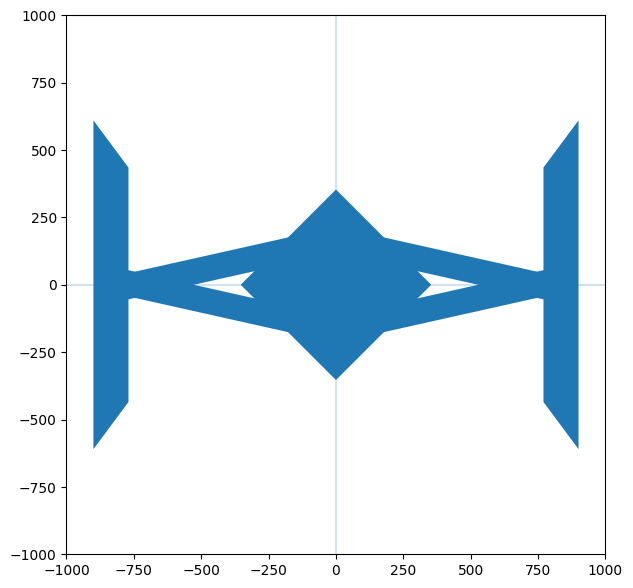

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
draw_axis(ax)
draw_object(ax)
plt.show()